## Loading and inspecting dataset



In [36]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

In [37]:
df = pd.read_csv("C:/Users/computer razavi/Desktop/heart.csv")


In [38]:
display(df.head())
df.info()


,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trtbps    303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalachh  303 non-null    int64  
 8   exng      303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slp       303 non-null    int64  
 11  caa       303 non-null    int64  
 12  thall     303 non-null    int64  
 13  output    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [39]:
missing_values = df.isnull().sum()
missing_values

age         0
sex         0
cp          0
trtbps      0
chol        0
fbs         0
restecg     0
thalachh    0
exng        0
oldpeak     0
slp         0
caa         0
thall       0
output      0
dtype: int64

In [40]:
target_column = 'output'
class_counts = df[target_column].value_counts()
class_counts

output
1    165
0    138
Name: count, dtype: int64

### Separating features and target

In [41]:
X = df.drop(columns = target_column)
y = df[target_column]
print(f"x shape is {X.shape}")
print(f"y shape is {y.shape}")


x shape is (303, 13)
y shape is (303,)


In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    test_size = 0.2,
    random_state = 42,
    stratify= y
)

In [43]:
print(f"x train shape is {X_train.shape}")
print(f"x test shape is {X_test.shape}")
print(f"train positive class is {y_train.mean():.2f}")
print(f"test positive class is {y_test.mean():.2f}")


x train shape is (242, 13)
x test shape is (61, 13)
train positive class is 0.55
test positive class is 0.54


# preprocessing and pipelines

In [44]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

## Differentiating Numerical and Categorical Features

In [45]:
num_features = ['age','trtbps','chol','thalachh','oldpeak']
cat_features = ['sex','cp','fbs','restecg','exng','slp','caa','thall' ]

print(f"Numerical features ({len(num_features)}): {num_features}")
print(f"Categorical features ({len(cat_features)}): {cat_features}")

Numerical features (5): ['age', 'trtbps', 'chol', 'thalachh', 'oldpeak']
Categorical features (8): ['sex', 'cp', 'fbs', 'restecg', 'exng', 'slp', 'caa', 'thall']


## Pipeline

In [46]:
#Although earlier I checked that there are no nulls in the dataset but i still use simple imputer as it is commonly used
numeric_transformer = Pipeline(steps = [
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])


In [47]:
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, num_features),
    ('cat', categorical_transformer, cat_features)
])

In [48]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"X_train processed shape is {X_train_processed.shape}")
print(f"X_test processed shape is {X_test_processed.shape}")


X_train processed shape is (242, 30)
X_test processed shape is (61, 30)


# Model training and evaluation

In [49]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

In [50]:
models = {
    "Logistic Regression" : LogisticRegression(random_state = 42),
    "Random Forest" : RandomForestClassifier(random_state = 42),
    "Support Vector Machine (SVM)" : SVC(probability = True, random_state = 42 )
}

trained_models = {}
model_performance = {}

### Training and evaluating each model

In [51]:
for name, classifier in models.items():    
    full_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', classifier)   
    ])

    full_pipeline.fit(X_train, y_train)

    y_pred = full_pipeline.predict(X_test)
    y_prob = full_pipeline.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)

    trained_models[name] = full_pipeline
    model_performance[name] = {"Accuracy": accuracy, "ROC_AUC": roc_auc}

    print(f"{name} training results:")
    print(f"Accuracy of {name}: {accuracy:.4f}")
    print(f"ROC-AUC of {name}: {roc_auc:.4f}\n")

Logistic Regression training results:
Accuracy of Logistic Regression: 0.8689
ROC-AUC of Logistic Regression: 0.9102

Random Forest training results:
Accuracy of Random Forest: 0.8197
ROC-AUC of Random Forest: 0.9167

Support Vector Machine (SVM) training results:
Accuracy of Support Vector Machine (SVM): 0.8361
ROC-AUC of Support Vector Machine (SVM): 0.9102



# Tuning and Evaluating the model

In [52]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, classification_report

In [53]:
# Because of the results we got, the model i use is Logistic regression
base_lr_pipeline = Pipeline(steps =[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state = 42, max_iter = 1000))
])

param_grid = {
    'classifier__C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
    'classifier__solver': ['lbfgs', 'saga']
}

grid_search = GridSearchCV(
    estimator = base_lr_pipeline,
    param_grid = param_grid,
    cv = 5,
    scoring = 'roc_auc',
    n_jobs = -1
)

grid_search.fit(X_train, y_train)
best_lr_pipeline = grid_search.best_estimator_

for param, val in grid_search.best_params_.items():
    print(f"{param}: {val}")

classifier__C: 0.1
classifier__solver: lbfgs


In [54]:
y_pred = best_lr_pipeline.predict(X_test)

print("Classifiacation Report:\n")
print(classification_report(y_test,y_pred))

cm = confusion_matrix(y_test,y_pred)

print("confusion matrix:\n")
print(cm)


Classifiacation Report:

              precision    recall  f1-score   support

           0       0.92      0.79      0.85        28
           1       0.84      0.94      0.89        33

    accuracy                           0.87        61
   macro avg       0.88      0.86      0.87        61
weighted avg       0.87      0.87      0.87        61

confusion matrix:

[[22  6]
 [ 2 31]]


## Plot of the confusion matrix

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

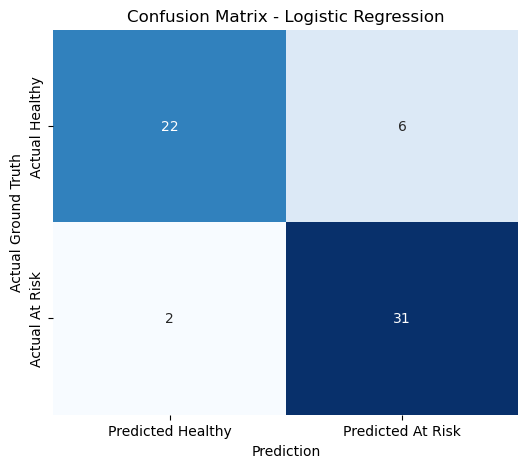

In [56]:
plt.figure(figsize = (6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Healthy', 'Predicted At Risk'],
            yticklabels=['Actual Healthy', 'Actual At Risk']
)
plt.xlabel('Prediction')
plt.ylabel('Actual Ground Truth')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

## Feature import and coefficients view

In [57]:
cat_encoder = best_lr_pipeline.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']

all_features = best_lr_pipeline.named_steps['preprocessor'].get_feature_names_out()

coefficients = best_lr_pipeline.named_steps['classifier'].coef_[0]

importance_df = pd.DataFrame({
    'Feature': all_features,
    'Coefficient': coefficients
}).sort_values(by='Coefficient', ascending=False)


print("Feature coefficients:\n")
display(importance_df)

Feature coefficients:



,Feature,Coefficient
21,cat__caa_0,0.552394
28,cat__thall_2,0.547823
9,cat__cp_2,0.379218
16,cat__exng_0,0.309990
5,cat__sex_0,0.305592
3,num__thalachh,0.288914
20,cat__slp_2,0.251448
10,cat__cp_3,0.196960
14,cat__restecg_1,0.139733
8,cat__cp_1,0.076845


# Running Predictions with an actual test input

In [58]:
X_test.head()

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall
179,57,1,0,150,276,0,0,112,1,0.6,1,1,1
197,67,1,0,125,254,1,1,163,0,0.2,1,2,3
285,46,1,0,140,311,0,1,120,1,1.8,1,2,3
194,60,1,2,140,185,0,0,155,0,3.0,1,0,2
188,50,1,2,140,233,0,1,163,0,0.6,1,1,3


In [59]:
test_patient = pd.DataFrame({
    'age': [58],
    'sex': [1],          # e.g., 1 = Male, 0 = Female
    'cp': [3],           # e.g., Chest pain type
    'trtbps': [130],   # Resting blood pressure
    'chol': [187],       # Cholesterol
    'fbs': [0],          # Fasting blood sugar > 120 mg/dl (0 = No, 1 = Yes)
    'restecg': [0],      # Resting ECG results
    'thalachh': [142],    # Maximum heart rate achieved
    'exng': [0],        # Exercise induced angina (0 = No, 1 = Yes)
    'oldpeak': [1.2],    # ST depression
    'slp': [1],        # Slope of peak exercise ST segment
    'caa': [2],           # Number of major vessels (0-3)
    'thall': [2]          # Thalassemia type
})

pred_outcome = best_lr_pipeline.predict(test_patient)[0]
pred_prob = best_lr_pipeline.predict_proba(test_patient)[0][1]

print(f"• Prediction:          {'At Risk (1)' if pred_outcome == 1 else 'Healthy (0)'}")
print(f"• Risk Probability:    {pred_prob * 100:.2f}%")

• Prediction:          At Risk (1)
• Risk Probability:    60.04%
